# Agreement, reliability and side bias (Colab-ready)

Starts from **`prepared/cleaned_training_responses.csv`** (output of notebook 1). **No predictor model** is fit here — only descriptive reliability and association measures.

Notebook 1 cleaned the file and showed basic structure. This notebook measures whether choices are **reproducible** and **associated with measurable structure**:

- how tight the side-A rate is when repeated pairs stay together
- whether two answers to the same ordered pair agree above chance (Cohen's κ)
- whether swapping the two photos follows the **photo** or the **side**
- whether image and cat win rates show up again on a fresh half of the pairs (split-half reliability)
- whether background fields go with the side chosen, and with each other
- whether the 508 blank-background rows differ in choice rate

Background fields are nominal → **Cramér's V**. Spearman is only for the three fields that have a natural order.

**Course / report link:** The side-adjusted image and cat strengths computed here are the empirical scores that a Bradley–Terry model (Chapter 7) tries to recover. Split-half reliability and pair-level bootstraps illustrate the validation principle emphasised in the midterm guidelines: keep whole pairs (or images/cats) out of held-out folds so repeated comparisons cannot leak. Low Cramér’s V with demographics already suggests that a pure demographic logistic model (Chapter 6) will have limited predictive power.

**Bottom line of the whole notebook:** a single response is noisy (κ ≈ 0.11); preference still carries a real **photo/cat** signal (negative swap correlation; cat split-half *r* ≈ 0.69); demographics barely move P(A); keep blank-background rows in overall rates.


## 0. Setup (Colab or local)

**Purpose:** find the cleaned CSV from notebook 1, create figure folders, and define constants/helpers.

**What this section does:**
- Searches common locations for `prepared/cleaned_training_responses.csv`
- Checks that required columns from notebook 1 are present
- Sets a fixed RNG seed (**21**) for bootstrap and split-half so results are reproducible
- Defines Wilson intervals, Cramér's V, Cohen's κ, pair helpers, and split-half reliability

**Bottom line:** if the cleaned file is missing, run notebook 1 first (or upload `cleaned_training_responses.csv` into a `prepared/` folder).


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, spearmanr

try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)


def find_cleaned_path() -> Path:
    candidates = [
        Path.cwd() / "prepared" / "cleaned_training_responses.csv",
        Path.cwd() / "cleaned_training_responses.csv",
        Path.cwd().parent / "prepared" / "cleaned_training_responses.csv",
        Path("/content") / "prepared" / "cleaned_training_responses.csv",
        Path("/content") / "cleaned_training_responses.csv",
        Path("/content/drive/MyDrive") / "prepared" / "cleaned_training_responses.csv",
        Path("/home/workdir/artifacts") / "prepared" / "cleaned_training_responses.csv",
    ]
    for p in candidates:
        if p.is_file():
            return p
    raise FileNotFoundError(
        "Could not find prepared/cleaned_training_responses.csv. "
        "Run notebook 1 first, or upload the cleaned CSV into a prepared/ folder."
    )


CLEANED_PATH = find_cleaned_path()
FIG_DIR = Path.cwd() / "model-checks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

DEMO_COLS = [
    "gender",
    "pet_history",
    "pet_care",
    "pet_contact",
    "future_pet",
    "mbti_ie",
]
LEVELS = {
    "gender": ["woman", "man"],
    "pet_history": ["current", "past", "never"],
    "pet_care": ["current_regular", "past_regular", "occasionally", "never"],
    "pet_contact": ["daily", "often", "sometimes", "rarely", "never"],
    "future_pet": ["yes", "unsure", "no"],
    "mbti_ie": ["E", "I", "unknown"],
}
ORDINAL = {
    "pet_history": {"current": 2, "past": 1, "never": 0},
    "pet_contact": {"daily": 4, "often": 3, "sometimes": 2, "rarely": 1, "never": 0},
    "future_pet": {"yes": 2, "unsure": 1, "no": 0},
}

REQUIRED_COLS = [
    "train_row_id",
    "a_cat",
    "b_cat",
    "a_image",
    "b_image",
    "choice",
    "comparison_type",
    "chose_a",
    "demo_complete",
    "ordered_pair_id",
    "unordered_pair_id",
    *DEMO_COLS,
]

SEED = 21
SPLIT_HALF_REPS_DEFAULT = 40
rng = np.random.default_rng(SEED)

train = pd.read_csv(CLEANED_PATH)
missing = [c for c in REQUIRED_COLS if c not in train.columns]
if missing:
    raise ValueError(
        f"Cleaned file is missing columns {missing}. "
        "Re-run notebook 1 so derived fields (chose_a, pair ids, demo_complete) exist."
    )
train["demo_complete"] = train["demo_complete"].astype(bool)
train["chose_a"] = train["chose_a"].astype(int)

print("CLEANED_PATH:", CLEANED_PATH.resolve())
print("FIG_DIR:", FIG_DIR.resolve())
print(f"{len(train):,} rows")
print(f"RNG seed: {SEED}")


CLEANED_PATH: /content/cleaned_training_responses.csv
FIG_DIR: /content/model-checks/figures
24,896 rows
RNG seed: 21


### Optional: upload cleaned CSV in Colab

**When to use:** only if setup could not find `prepared/cleaned_training_responses.csv`.

Upload the file produced by notebook 1, then re-run the setup cell (or set the path manually in the upload cell).

**Bottom line:** skip this section when setup already printed a valid `CLEANED_PATH`.


In [ ]:
# Uncomment in Google Colab if needed:
# from google.colab import files
# from pathlib import Path
# uploaded = files.upload()  # choose cleaned_training_responses.csv
# Path("prepared").mkdir(exist_ok=True)
# if "cleaned_training_responses.csv" in uploaded:
#     Path("prepared/cleaned_training_responses.csv").write_bytes(
#         uploaded["cleaned_training_responses.csv"]
#     )
#     print("Saved to prepared/cleaned_training_responses.csv — re-run the setup cell.")


## Helpers

**Purpose:** shared statistical functions used in every section below.

| Function | Role |
|----------|------|
| `wilson_interval` | 95% CI for a proportion |
| `cramers_v` | Association between two categorical variables |
| `cohen_kappa` | Agreement above chance for two binary response vectors |
| `repeated_responses` | First/second row for ordered pairs answered exactly twice |
| `both_orientations` | Two layouts of the same unordered pair (deterministic order by `a_image`) |
| `side_adjusted` | Cat/image win rates after removing overall side-A bias |
| `split_half_reliability` | Correlation of strengths when whole unordered pairs are held out of each half |
| `kappa_bootstrap_ci` | Pair-level bootstrap CI for κ (ordered pairs) |

**Bottom line:** split-half assigns **unordered pairs** to halves so both orientations of a comparison cannot inflate reliability by landing in different halves.


In [ ]:
def wilson_interval(successes, n, z=1.96):
    successes = float(successes)
    n = float(n)
    p = successes / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    margin = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - margin, centre + margin


def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p_value, dof, _ = chi2_contingency(table)
    n = table.to_numpy().sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return float(v), float(p_value), int(dof)


def cohen_kappa(y1, y2):
    y1 = np.asarray(y1)
    y2 = np.asarray(y2)
    observed = np.mean(y1 == y2)
    expected = np.mean(y1) * np.mean(y2) + (1 - np.mean(y1)) * (1 - np.mean(y2))
    if expected >= 1.0:
        return float("nan"), float(observed), float(expected)
    return float((observed - expected) / (1 - expected)), float(observed), float(expected)


def repeated_responses(df):
    ordered = df.sort_values(["ordered_pair_id", "train_row_id"])
    counts = ordered.groupby("ordered_pair_id").size()
    repeated = ordered[ordered["ordered_pair_id"].isin(counts[counts == 2].index)].copy()
    repeated["_k"] = repeated.groupby("ordered_pair_id").cumcount()
    first = repeated[repeated["_k"] == 0].set_index("ordered_pair_id")
    second = repeated[repeated["_k"] == 1].set_index("ordered_pair_id").loc[first.index]
    return first, second


def both_orientations(df):
    """Two orientations of each unordered pair.

    Orientations are ordered deterministically by a_image path (not by time).
    Each orientation's chose_a is the mean over responses in that layout.
    """
    grouped = df.groupby(["unordered_pair_id", "ordered_pair_id"], as_index=False).agg(
        chose_a=("chose_a", "mean"),
        n=("chose_a", "size"),
        a_image=("a_image", "first"),
        b_image=("b_image", "first"),
        comparison_type=("comparison_type", "first"),
    )
    n_orient = grouped.groupby("unordered_pair_id").size()
    both = grouped[grouped["unordered_pair_id"].isin(n_orient[n_orient == 2].index)]
    both = both.sort_values(["unordered_pair_id", "a_image"])
    first = both.groupby("unordered_pair_id", as_index=False).nth(0).reset_index(drop=True)
    second = both.groupby("unordered_pair_id", as_index=False).nth(1).reset_index(drop=True)
    return first, second


def side_adjusted(df, id_a, id_b):
    p_side = float(df["chose_a"].mean())
    long = pd.concat(
        [
            pd.DataFrame(
                {
                    "id": df[id_a].to_numpy(),
                    "resid": df["chose_a"].to_numpy() - p_side,
                    "won": df["chose_a"].to_numpy(),
                }
            ),
            pd.DataFrame(
                {
                    "id": df[id_b].to_numpy(),
                    "resid": (1 - df["chose_a"].to_numpy()) - (1 - p_side),
                    "won": 1 - df["chose_a"].to_numpy(),
                }
            ),
        ],
        ignore_index=True,
    )
    scores = long.groupby("id").agg(n=("won", "size"), win_rate=("won", "mean"), resid=("resid", "mean"))
    scores["null_se"] = np.sqrt(p_side * (1 - p_side) / scores["n"])
    return scores, p_side


def split_half_reliability(df, id_a, id_b, min_n, reps):
    """Correlation of side-adjusted strengths when whole pairs are held out.

    Each unordered pair is assigned to one half, so the two orientations of a
    comparison cannot inflate the correlation by landing in different halves.
    """
    pairs = df["unordered_pair_id"].unique()
    correlations = []
    kept = []
    for _ in range(reps):
        chosen = set(rng.choice(pairs, size=len(pairs) // 2, replace=False))
        halves = [
            df[df["unordered_pair_id"].isin(chosen)],
            df[~df["unordered_pair_id"].isin(chosen)],
        ]
        scores = [side_adjusted(half, id_a, id_b)[0] for half in halves]
        joined = scores[0].join(scores[1], lsuffix="_1", rsuffix="_2")
        joined = joined[(joined["n_1"] >= min_n) & (joined["n_2"] >= min_n)]
        kept.append(len(joined))
        if len(joined) > 30:
            correlations.append(float(np.corrcoef(joined["resid_1"], joined["resid_2"])[0, 1]))
    if not correlations:
        return float("nan"), float("nan"), int(np.median(kept)) if kept else 0
    return float(np.mean(correlations)), float(np.std(correlations, ddof=1)), int(np.median(kept))


def kappa_bootstrap_ci(first, second, mask, n_boot=1000):
    """Bootstrap CI for kappa by resampling ordered pairs (rows of first/second)."""
    idx = np.flatnonzero(mask)
    if len(idx) < 10:
        return float("nan"), float("nan")
    y1 = first["chose_a"].to_numpy()
    y2 = second["chose_a"].to_numpy()
    kappas = []
    for _ in range(n_boot):
        draw = rng.choice(idx, size=len(idx), replace=True)
        k, _, _ = cohen_kappa(y1[draw], y2[draw])
        if np.isfinite(k):
            kappas.append(k)
    return float(np.quantile(kappas, 0.025)), float(np.quantile(kappas, 0.975))


print("helpers ready")


helpers ready


## 1. Side A

**This section answers:** *How often do people choose A, and is that rate tightly estimated?*

**What this analysis is testing:** overall side bias, with two uncertainty treatments:
- **Wilson** — treats every row as independent
- **Pair bootstrap** — resamples **unordered pairs** so repeated showings of the same photos stay together

**How to read the result (this dataset):**
- Point estimate **P(A) ≈ 0.519**
- Wilson and pair-bootstrap 95% CIs both about **0.513–0.525**

**Bottom line:** mild, real preference for side A. A useful baseline for models is ~52%, not 50%. Clustering pairs barely changes the CI here because the sample is large.


In [ ]:
k_a = int(train["chose_a"].sum())
n_rows = len(train)
p_a = k_a / n_rows
wilson_lo, wilson_hi = wilson_interval(k_a, n_rows)

pair_totals = train.groupby("unordered_pair_id")["chose_a"].agg(["sum", "count"])
sums = pair_totals["sum"].to_numpy()
counts = pair_totals["count"].to_numpy()
draw = rng.integers(0, len(pair_totals), size=(2000, len(pair_totals)))
boot = sums[draw].sum(axis=1) / counts[draw].sum(axis=1)
boot_lo, boot_hi = np.quantile(boot, [0.025, 0.975])

side_summary = pd.DataFrame(
    {
        "estimate": [p_a, p_a],
        "low_95": [wilson_lo, boot_lo],
        "high_95": [wilson_hi, boot_hi],
    },
    index=["Wilson, rows independent", "Bootstrap, pairs clustered"],
)
display(side_summary.round(4))
print(f"P(choose A) = {p_a:.4f}")
print(f"Wilson {wilson_lo:.4f} to {wilson_hi:.4f}")
print(f"pair bootstrap {boot_lo:.4f} to {boot_hi:.4f}")


,estimate,low_95,high_95
"Wilson, rows independent",0.519,0.5128,0.5252
"Bootstrap, pairs clustered",0.519,0.5133,0.5248


P(choose A) = 0.5190
Wilson 0.5128 to 0.5252
pair bootstrap 0.5133 to 0.5248


## 2. Agreement on a repeated ordered pair

**This section answers:** *When the same pair in the same left/right order is answered twice, do the answers match above chance?*

**What this analysis is testing:** Cohen's κ on ordered pairs with exactly two responses. The two rows are **two responses**, not necessarily the same person (there is no respondent id). Call this **inter-response agreement on a pair**, not test–retest reliability of one annotator.

**How to read the result (this dataset):**

| Subset | Pairs | Observed agree | κ | 95% CI (pair bootstrap) |
|--------|------:|---------------:|------:|-------------------------|
| All repeated | 9,733 | 0.557 | **0.114** | 0.096 – 0.135 |
| Within-cat | 983 | 0.525 | **0.050** | −0.015 – 0.114 |
| Between-cats | 8,750 | 0.561 | **0.121** | 0.100 – 0.141 |

κ near 0 means agreement is no better than the match rate implied by the overall share of A. Within-cat κ is compatible with zero at 95%.

**Bottom line:** a second response mostly **fails to reproduce** the first. Between-cat agreement is only slightly better than within-cat. Single binary labels are noisy — models should expect substantial irreducible error.


,pairs,observed_agreement,chance_agreement,kappa,kappa_low_95,kappa_high_95
subset,,,,,,
all repeated pairs,9733,0.557,0.501,0.114,0.096,0.135
within_cat,983,0.525,0.500,0.050,-0.015,0.114
between_cats,8750,0.561,0.501,0.121,0.100,0.141


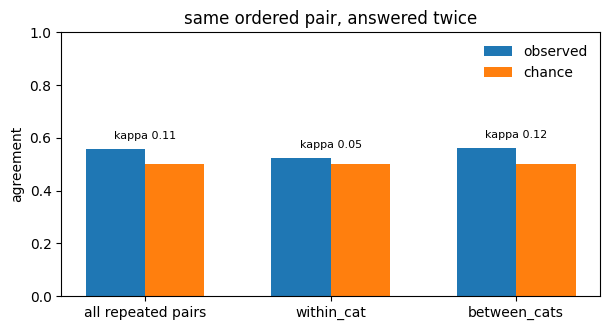

In [ ]:
first, second = repeated_responses(train)
agreement_rows = []
for label, mask in [
    ("all repeated pairs", np.ones(len(first), dtype=bool)),
    ("within_cat", first["comparison_type"].eq("within_cat").to_numpy()),
    ("between_cats", first["comparison_type"].eq("between_cats").to_numpy()),
]:
    kappa, observed, expected = cohen_kappa(first.loc[mask, "chose_a"], second.loc[mask, "chose_a"])
    k_lo, k_hi = kappa_bootstrap_ci(first, second, mask, n_boot=1000)
    agreement_rows.append(
        {
            "subset": label,
            "pairs": int(mask.sum()),
            "observed_agreement": observed,
            "chance_agreement": expected,
            "kappa": kappa,
            "kappa_low_95": k_lo,
            "kappa_high_95": k_hi,
        }
    )
agreement = pd.DataFrame(agreement_rows).set_index("subset")
display(agreement.round(3))

fig, ax = plt.subplots(figsize=(6.2, 3.4))
x = np.arange(len(agreement))
ax.bar(x - 0.16, agreement["observed_agreement"], width=0.32, color="C0", label="observed")
ax.bar(x + 0.16, agreement["chance_agreement"], width=0.32, color="C1", label="chance")
ax.set_xticks(x, agreement.index, rotation=0)
ax.set_ylim(0, 1)
ax.set_ylabel("agreement")
for i, row in enumerate(agreement.itertuples()):
    ax.text(i, row.observed_agreement + 0.03, f"kappa {row.kappa:.2f}", ha="center", va="bottom", fontsize=8)
ax.legend(frameon=False)
ax.set_title("same ordered pair, answered twice")
fig.tight_layout()
fig.savefig(FIG_DIR / "agreement_kappa.png", bbox_inches="tight")
plt.show()


## 3. Swapping the photos

**This section answers:** *If the same two photos are shown with sides flipped, does preference follow the photo or the side?*

**What this analysis is testing:** for unordered pairs that appear in **both** orientations, correlate mean `chose_a` across orientations, and among decisive pairs (mean not tied at 0.5) measure whether the **same image** or the **same side** wins.

Unit of analysis: one rate per orientation per unordered pair (not one raw row).

**How to read the result (this dataset):**
- Corr(`chose_a`) across orientations ≈ **−0.14** overall (more negative for between-cat)
- Same image wins both orders ≈ **0.60** of decisive pairs; same side only ~0.40

A negative correlation is expected if people follow the photo: when the stronger image moves from A to B, `chose_a` falls.

**Bottom line:** there is a **photo effect on top of side bias**. Preferences are not only “click left.” Image identity matters — consistent with notebook 1’s win-gap pattern.


,pairs,corr_chose_a,decisive_pairs,same_image,same_side
subset,,,,,
all both-order pairs,7114,-0.138,3639,0.595,0.405
within_cat,888,-0.068,521,0.545,0.455
between_cats,6226,-0.149,3118,0.604,0.396


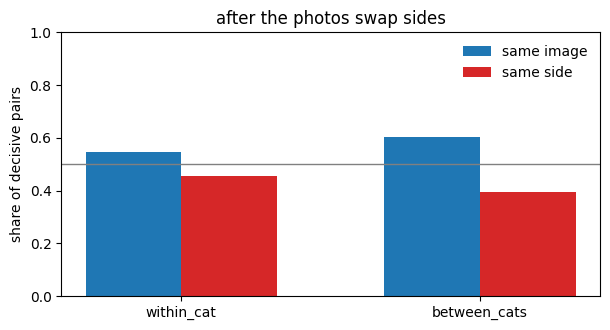

In [ ]:
orient_a, orient_b = both_orientations(train)
assert orient_a["unordered_pair_id"].equals(orient_b["unordered_pair_id"])

decisive = (orient_a["chose_a"] != 0.5) & (orient_b["chose_a"] != 0.5)
winner_a = np.where(orient_a["chose_a"] > 0.5, orient_a["a_image"], orient_a["b_image"])
winner_b = np.where(orient_b["chose_a"] > 0.5, orient_b["a_image"], orient_b["b_image"])
same_image = winner_a == winner_b
same_side = ((orient_a["chose_a"] > 0.5) & (orient_b["chose_a"] > 0.5)) | (
    (orient_a["chose_a"] < 0.5) & (orient_b["chose_a"] < 0.5)
)

reversal_rows = []
for label, mask in [
    ("all both-order pairs", np.ones(len(orient_a), dtype=bool)),
    ("within_cat", orient_a["comparison_type"].eq("within_cat").to_numpy()),
    ("between_cats", orient_a["comparison_type"].eq("between_cats").to_numpy()),
]:
    correlation = float(np.corrcoef(orient_a.loc[mask, "chose_a"], orient_b.loc[mask, "chose_a"])[0, 1])
    decided = decisive.to_numpy() & mask
    reversal_rows.append(
        {
            "subset": label,
            "pairs": int(mask.sum()),
            "corr_chose_a": correlation,
            "decisive_pairs": int(decided.sum()),
            "same_image": float(same_image[decided].mean()) if decided.sum() else float("nan"),
            "same_side": float(same_side.to_numpy()[decided].mean()) if decided.sum() else float("nan"),
        }
    )
reversal = pd.DataFrame(reversal_rows).set_index("subset")
display(reversal.round(3))

plot_reversal = reversal.loc[["within_cat", "between_cats"]]
fig, ax = plt.subplots(figsize=(6.2, 3.4))
x = np.arange(len(plot_reversal))
ax.bar(x - 0.16, plot_reversal["same_image"], width=0.32, color="C0", label="same image")
ax.bar(x + 0.16, plot_reversal["same_side"], width=0.32, color="C3", label="same side")
ax.axhline(0.5, color="0.5", lw=1)
ax.set_xticks(x, plot_reversal.index)
ax.set_ylim(0, 1)
ax.set_ylabel("share of decisive pairs")
ax.legend(frameon=False, loc="upper right")
ax.set_title("after the photos swap sides")
fig.tight_layout()
fig.savefig(FIG_DIR / "reversal_consistency.png", bbox_inches="tight")
plt.show()


## 4. Do the win rates replicate? (split-half reliability)

**This section answers:** *If we split the pairs in half, do cats (or images) that look strong in one half still look strong in the other?*

**What this analysis is testing:** side-adjusted residual strength for each image or cat, then correlation across random halves. Whole **unordered pairs** are assigned to one half only (so both orientations of a comparison cannot leak into both halves).

Specs (unit, data slice, min appearances per half, reps):
- images, all rows — min_n 5, 40 reps
- images, within_cat — min_n 3, 30 reps
- images, between_cats — min_n 4, 30 reps
- cats, between_cats — min_n 8, 30 reps

**How to read the result (this dataset):**

| Unit | Split-half *r* | sd across reps | Units in both halves (median) |
|------|---------------:|---------------:|------------------------------:|
| Images, all | **~0.37** | ~0.02 | ~1,250 |
| Images, within_cat | **~0.14** | ~0.05 | ~178 |
| Images, between_cats | **~0.36** | ~0.01 | ~1,249 |
| **Cats, between_cats** | **~0.70** | ~0.03 | 237 |

Left plot: image residuals vs appearances (±2 null SE band). Right plot: split-half *r* with ±1 sd across reps. Within-cat image reliability is noisiest (few units survive the min_n cut in both halves).

**Bottom line:** the preference signal that **replicates** is mostly **which cat**. Within-cat photo differences are much weaker. Modeling and feature design should prioritize cat-level signal over fine-grained same-cat image nuance.

**Validation note (course / report):** whole unordered pairs are assigned to one half only. This matches the midterm guideline that repeated pairs, images or cats should not be shared across splits when the claim is about generalisation to new comparisons. The same principle should be used when fitting Bradley–Terry strengths or any predictive model later.

**Link to Chapter 7:** the residual win rates stored in `score_tables` are empirical estimates of latent strengths. A Bradley–Terry model places a logistic link on score differences and can regularise or pool those strengths; the split-half correlations above give a lower bound on how stable any such ranking can be.

**Comparison graph (Chapter 7):** because the same cats and images appear in many pairs, the preference data form a comparison graph. Reliability estimates and later models therefore assign whole unordered pairs (or whole images/cats) to folds — not individual rows — so that information cannot leak across the graph.


,units,median_appearances,signal_ratio,outside_2se,split_half_r,split_half_sd,units_in_both_halves
unit,,,,,,,
"images, all rows",1296,39.0,2.472,0.223,0.366,0.018,1250
"images, within_cat",1251,5.0,1.156,0.062,0.142,0.054,178
"images, between_cats",1296,34.0,2.502,0.231,0.362,0.014,1249
"cats, between_cats",237,186.0,6.650,0.418,0.700,0.027,237


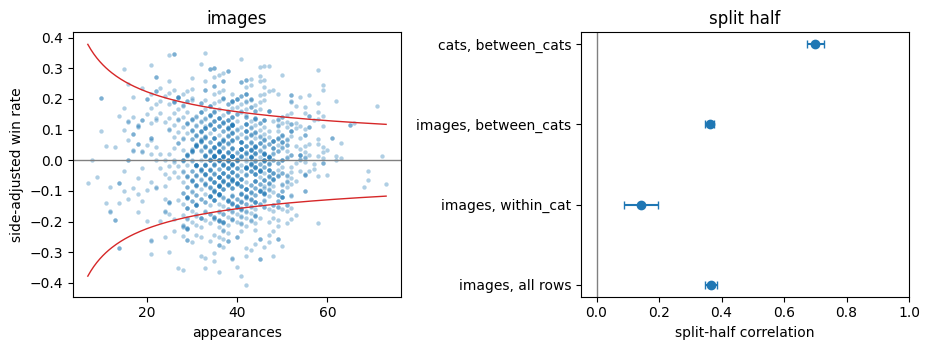

In [ ]:
strength_specs = [
    ("images, all rows", train, "a_image", "b_image", 5, 40),
    ("images, within_cat", train[train["comparison_type"] == "within_cat"].copy(), "a_image", "b_image", 3, 30),
    ("images, between_cats", train[train["comparison_type"] == "between_cats"].copy(), "a_image", "b_image", 4, 30),
    ("cats, between_cats", train[train["comparison_type"] == "between_cats"].copy(), "a_cat", "b_cat", 8, 30),
]

strength_rows = []
score_tables = {}
for label, data, id_a, id_b, min_n, reps in strength_specs:
    scores, _ = side_adjusted(data, id_a, id_b)
    score_tables[label] = scores
    signal = float((scores["resid"] ** 2).mean() / (scores["null_se"] ** 2).mean())
    reliability, reliability_sd, n_kept = split_half_reliability(data, id_a, id_b, min_n, reps)
    strength_rows.append(
        {
            "unit": label,
            "units": len(scores),
            "median_appearances": float(scores["n"].median()),
            "signal_ratio": signal,
            "outside_2se": float((scores["resid"].abs() > 2 * scores["null_se"]).mean()),
            "split_half_r": reliability,
            "split_half_sd": reliability_sd,
            "units_in_both_halves": n_kept,
        }
    )
strength = pd.DataFrame(strength_rows).set_index("unit")
display(strength.round(3))

image_scores = score_tables["images, all rows"]
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.6))
axes[0].scatter(image_scores["n"], image_scores["resid"], s=10, alpha=0.35, color="C0", linewidths=0)
grid = np.linspace(image_scores["n"].min(), image_scores["n"].max(), 200)
band = 2 * np.sqrt(p_a * (1 - p_a) / grid)
axes[0].plot(grid, band, color="C3", lw=1)
axes[0].plot(grid, -band, color="C3", lw=1)
axes[0].axhline(0, color="0.5", lw=1)
axes[0].set_xlabel("appearances")
axes[0].set_ylabel("side-adjusted win rate")
axes[0].set_title("images")

axes[1].errorbar(
    strength["split_half_r"],
    np.arange(len(strength)),
    xerr=strength["split_half_sd"],
    fmt="o",
    color="C0",
    capsize=3,
)
axes[1].axvline(0, color="0.5", lw=1)
axes[1].set_yticks(np.arange(len(strength)), strength.index)
axes[1].set_xlim(-0.05, 1)
axes[1].set_xlabel("split-half correlation")
axes[1].set_title("split half")
fig.tight_layout()
fig.savefig(FIG_DIR / "strength_reliability.png", bbox_inches="tight")
plt.show()


### Export side-adjusted strengths for later modelling

Save the two most useful score tables so a Bradley–Terry or ranking notebook can start from the same empirical strengths without re-running the reliability loop.

- `prepared/side_adjusted_image_scores.csv` — all rows, image-level
- `prepared/side_adjusted_cat_scores_between.csv` — between-cat rows, cat-level


In [ ]:
PREPARED_DIR = CLEANED_PATH.parent if CLEANED_PATH.name == "cleaned_training_responses.csv" else Path.cwd() / "prepared"
PREPARED_DIR.mkdir(parents=True, exist_ok=True)

img_out = PREPARED_DIR / "side_adjusted_image_scores.csv"
cat_out = PREPARED_DIR / "side_adjusted_cat_scores_between.csv"

image_scores = score_tables["images, all rows"].copy()
image_scores = image_scores.reset_index().rename(columns={"id": "image"})
image_scores.to_csv(img_out, index=False)

cat_scores = score_tables["cats, between_cats"].copy()
cat_scores = cat_scores.reset_index().rename(columns={"id": "cat"})
cat_scores.to_csv(cat_out, index=False)

print(f"Wrote {img_out.resolve()}  ({len(image_scores):,} images)")
print(f"Wrote {cat_out.resolve()}  ({len(cat_scores):,} cats)")
display(image_scores.head(3))
display(cat_scores.head(3))


Wrote /content/side_adjusted_image_scores.csv  (1,296 images)
Wrote /content/side_adjusted_cat_scores_between.csv  (237 cats)


,image,n,win_rate,resid,null_se
0,cat_000002/cat_000002_0001.jpg,25,0.760000,0.259240,0.099928
1,cat_000002/cat_000002_0002.jpg,23,0.695652,0.191522,0.104182
2,cat_000002/cat_000002_0003.jpg,20,0.550000,0.048100,0.111723


,cat,n,win_rate,resid,null_se
0,cat_000002,191,0.643979,0.143464,0.036151
1,cat_000005,191,0.696335,0.196232,0.036151
2,cat_000007,198,0.560606,0.060805,0.035506


## 5. Background and the side chosen

**This section answers:** *Do gender, pet experience, or MBTI I/E move the chance of choosing A? Are background fields tied to each other?*

**What this analysis is testing:**
- Cramér's V between each background field and `choice` (plus rate span = max−min group P(A))
- Spearman ρ for the three ordered fields vs `chose_a`
- Wilson CIs for P(A) by group (plot)
- Cramér's V **among** background fields (heatmap)

Only **`demo_complete`** rows are used here (notebook 1's flag).

**How to read the result (this dataset):**
- V with choice all about **0.01–0.05** (weak); rate spans only a few percentage points
- Spearman on ordinal pet fields also near zero
- Among background fields, associations are **strong** (e.g. history–care V ≈ 0.67)

**Bottom line:** annotator background is a poor predictor of A vs B. Strong structure exists *between* background fields (consistent profiles), not with the side chosen. Focus modeling on cats/images (and side), not demographics.


,cramers_v,p_value,dof,rate_span
field,,,,
gender,0.0081,0.2082,1,0.0082
pet_history,0.0342,0.0000,2,0.0380
pet_care,0.0257,0.0011,3,0.0339
pet_contact,0.0196,0.0526,4,0.0227
future_pet,0.0317,0.0000,2,0.0392
mbti_ie,0.0478,0.0000,2,0.0534


,spearman_rho,p_value
field,,
pet_history,-0.0323,0.0000
pet_contact,-0.0055,0.3862
future_pet,0.0317,0.0000


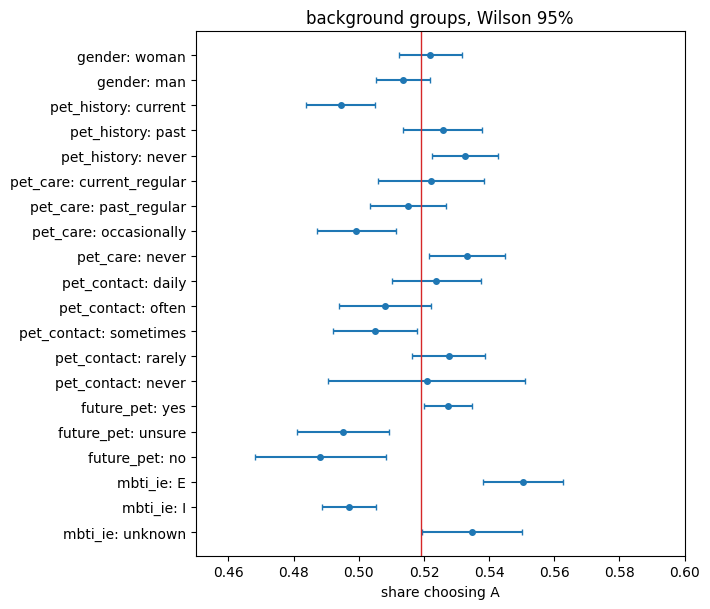

,gender,pet_history,pet_care,pet_contact,future_pet,mbti_ie
gender,1.00,0.08,0.19,0.20,0.24,0.13
pet_history,0.08,1.00,0.67,0.48,0.13,0.14
pet_care,0.19,0.67,1.00,0.51,0.19,0.12
pet_contact,0.20,0.48,0.51,1.00,0.22,0.23
future_pet,0.24,0.13,0.19,0.22,1.00,0.13
mbti_ie,0.13,0.14,0.12,0.23,0.13,1.00


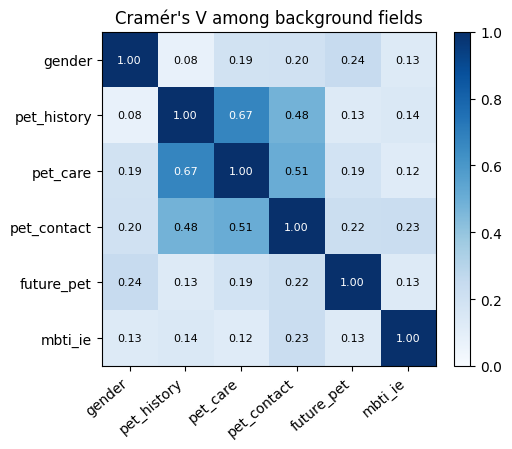

In [ ]:
complete = train[train["demo_complete"]].copy()
association_rows = []
rate_rows = []
for col in DEMO_COLS:
    v, p_value, dof = cramers_v(complete[col], complete["choice"])
    rates = complete.groupby(col)["chose_a"].agg(["mean", "sum", "size"])
    association_rows.append(
        {
            "field": col,
            "cramers_v": v,
            "p_value": p_value,
            "dof": dof,
            "rate_span": float(rates["mean"].max() - rates["mean"].min()),
        }
    )
    for level in LEVELS[col]:
        row = rates.loc[level]
        low, high = wilson_interval(row["sum"], row["size"])
        rate_rows.append(
            {
                "label": f"{col}: {level}",
                "rate": row["mean"],
                "low": low,
                "high": high,
                "n": int(row["size"]),
            }
        )

association = pd.DataFrame(association_rows).set_index("field")
display(association.round(4))

rank_rows = []
for col, coding in ORDINAL.items():
    coded = complete[col].map(coding)
    rho, p_value = spearmanr(coded, complete["chose_a"])
    rank_rows.append({"field": col, "spearman_rho": rho, "p_value": p_value})
display(pd.DataFrame(rank_rows).set_index("field").round(4))

rates = pd.DataFrame(rate_rows).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.2, 6.2))
y = np.arange(len(rates))
ax.errorbar(
    rates["rate"],
    y,
    xerr=[rates["rate"] - rates["low"], rates["high"] - rates["rate"]],
    fmt="o",
    color="C0",
    capsize=2,
    markersize=4,
)
ax.axvline(p_a, color="C3", lw=1)
ax.set_yticks(y, rates["label"])
ax.set_xlabel("share choosing A")
ax.set_xlim(0.45, 0.60)
ax.set_title("background groups, Wilson 95%")
fig.tight_layout()
fig.savefig(FIG_DIR / "choice_rate_intervals.png", bbox_inches="tight")
plt.show()

v_matrix = pd.DataFrame(index=DEMO_COLS, columns=DEMO_COLS, dtype=float)
for left in DEMO_COLS:
    for right in DEMO_COLS:
        if left == right:
            v_matrix.loc[left, right] = 1.0
        elif pd.isna(v_matrix.loc[left, right]):
            v, _, _ = cramers_v(complete[left], complete[right])
            v_matrix.loc[left, right] = v
            v_matrix.loc[right, left] = v
display(v_matrix.round(2))

fig, ax = plt.subplots(figsize=(5.6, 4.6))
image = ax.imshow(v_matrix.to_numpy(dtype=float), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(DEMO_COLS)), DEMO_COLS, rotation=40, ha="right")
ax.set_yticks(range(len(DEMO_COLS)), DEMO_COLS)
for i in range(len(DEMO_COLS)):
    for j in range(len(DEMO_COLS)):
        value = float(v_matrix.iloc[i, j])
        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value >= 0.55 else "black",
        )
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("Cramér's V among background fields")
fig.tight_layout()
fig.savefig(FIG_DIR / "background_cramers_v.png", bbox_inches="tight")
plt.show()


## 6. Blank background rows

**This section answers:** *Are the 508 rows notebook 1 kept different in choice behavior?*

**What this analysis is testing:** P(A) and share within-cat for missing vs complete background; agreement when one of two responses on a pair is blank; sensitivity of overall P(A) if blanks were dropped.

**How to read the result (this dataset):**
- Blank rows: P(A) ≈ **0.604** (n = 508)
- Complete rows: P(A) ≈ **0.517** (n = 24,388)
- Overall P(A) with blanks ≈ 0.519; without blanks ≈ 0.517 — small shift, but blanks are clearly different
- Pairs with one blank + one complete: agreement ~0.54 (similar to general noise levels)

**Bottom line:** notebook 1 was right to **keep** these rows for overall rates and exclude them only from background breakdowns (`demo_complete`). Dropping them would discard a real behavioral difference and slightly understate P(A).


In [ ]:
missing_rows = []
for label, mask in [
    ("background missing", ~train["demo_complete"]),
    ("background complete", train["demo_complete"]),
]:
    subset = train.loc[mask]
    low, high = wilson_interval(subset["chose_a"].sum(), len(subset))
    missing_rows.append(
        {
            "rows": label,
            "n": len(subset),
            "share_chose_a": subset["chose_a"].mean(),
            "low_95": low,
            "high_95": high,
            "share_within_cat": (subset["comparison_type"] == "within_cat").mean(),
        }
    )
missing_summary = pd.DataFrame(missing_rows).set_index("rows")
display(missing_summary.round(3))

# Sensitivity: overall P(A) with vs without blank-background rows
p_with = train["chose_a"].mean()
p_without = train.loc[train["demo_complete"], "chose_a"].mean()
print(f"P(A) with blank rows:    {p_with:.4f}  (n = {len(train):,})")
print(f"P(A) without blank rows: {p_without:.4f}  (n = {int(train['demo_complete'].sum()):,})")

partner_counts = train.groupby("ordered_pair_id")["demo_complete"].agg(["sum", "size"])
one_missing = partner_counts[(partner_counts["size"] == 2) & (partner_counts["sum"] == 1)]
paired = train[train["ordered_pair_id"].isin(one_missing.index)].sort_values(
    ["ordered_pair_id", "train_row_id"]
)
paired = paired.copy()
paired["_k"] = paired.groupby("ordered_pair_id").cumcount()
left = paired[paired["_k"] == 0].set_index("ordered_pair_id")
right = paired[paired["_k"] == 1].set_index("ordered_pair_id").loc[left.index]
agree = float(np.mean(left["choice"].to_numpy() == right["choice"].to_numpy()))
blank_cats = pd.unique(train.loc[~train["demo_complete"], ["a_cat", "b_cat"]].values.ravel()).size
blank_ids = train.loc[~train["demo_complete"], "train_row_id"]
print("pairs with one blank and one complete response:", len(one_missing))
print("those two agree:", round(agree, 3))
print("cats on a blank row:", blank_cats)
print("blank ids run from", blank_ids.iloc[0], "to", blank_ids.iloc[-1])


,n,share_chose_a,low_95,high_95,share_within_cat
rows,,,,,
background missing,508,0.604,0.561,0.646,0.096
background complete,24388,0.517,0.511,0.523,0.121


P(A) with blank rows:    0.5190  (n = 24,896)
P(A) without blank rows: 0.5172  (n = 24,388)
pairs with one blank and one complete response: 401
those two agree: 0.539
cats on a blank row: 234
blank ids run from TR000027 to TR024873


## 7. Reading the numbers

**Purpose:** one place that ties every metric to a modeling/EDA implication.

| Finding | Interpretation |
|---------|----------------|
| κ ≈ 0.11 | A second response mostly fails to reproduce the first — labels are noisy |
| Swap corr negative; same image wins ~60% | Photo effect on top of side bias |
| Cat split-half *r* ≈ 0.69 vs within-cat image *r* ≈ 0.15 | Replicable signal is **which cat** |
| Cramér's V with choice ≲ 0.05 | Background barely moves the side rate |
| Blank rows P(A) ≈ 0.60 vs complete ≈ 0.52 | Keep blanks in overall rates; exclude from demographic models |

**Course modelling implications:**
- Prefer **cat-level** (or strong image) features over pure demographics for any predictive model.
- Use the exported side-adjusted scores as a baseline ranking; a Bradley–Terry model (Chapter 7) can refine them under a logistic likelihood on score differences.
- Because cats and images **repeat across pairs**, the data form a comparison graph (Chapter 7). Train/validation splits for logistic regression, BT, or forests must keep whole unordered pairs (or whole images/cats) together; random row splits cause leakage.
- Demographics are still useful as *covariates* or for stratified interpretation even if their marginal association with choice is weak.
- Weak within-cat image reliability already hints that a single score per cat may be incomplete for fine-grained photo preference — motivation for image features or a shared ranking function later (Chapter 7 “Learning a Ranking Function for New Items”).


In [ ]:
print(f"side A {p_a:.3f}   pair bootstrap 95% {boot_lo:.3f} to {boot_hi:.3f}")
print("kappa")
for idx, row in agreement.iterrows():
    print(
        f"  {idx}: {row.kappa:.3f}   agreement {row.observed_agreement:.3f}   "
        f"95% CI {row.kappa_low_95:.3f} to {row.kappa_high_95:.3f}"
    )
print("swap correlation of chose_a")
for idx, row in reversal.iterrows():
    print(f"  {idx}: {row.corr_chose_a:.3f}   same image {row.same_image:.3f}")
print("split-half r")
for idx, row in strength.iterrows():
    print(f"  {idx}: {row.split_half_r:.3f}   sd {row.split_half_sd:.3f}   units both halves {int(row.units_in_both_halves)}")
print("Cramér's V with choice (and rate span)")
for idx, row in association.iterrows():
    print(f"  {idx}: V={row.cramers_v:.3f}   rate_span={row.rate_span:.3f}")
print(
    "background V  "
    f"history-care {v_matrix.loc['pet_history', 'pet_care']:.2f}  "
    f"care-contact {v_matrix.loc['pet_care', 'pet_contact']:.2f}  "
    f"history-contact {v_matrix.loc['pet_history', 'pet_contact']:.2f}"
)
print(
    f"blank rows choose A at {missing_summary.loc['background missing', 'share_chose_a']:.3f}; "
    f"complete rows at {missing_summary.loc['background complete', 'share_chose_a']:.3f}"
)


side A 0.519   pair bootstrap 95% 0.513 to 0.525
kappa
  all repeated pairs: 0.114   agreement 0.557   95% CI 0.096 to 0.135
  within_cat: 0.050   agreement 0.525   95% CI -0.015 to 0.114
  between_cats: 0.121   agreement 0.561   95% CI 0.100 to 0.141
swap correlation of chose_a
  all both-order pairs: -0.138   same image 0.595
  within_cat: -0.068   same image 0.545
  between_cats: -0.149   same image 0.604
split-half r
  images, all rows: 0.366   sd 0.018   units both halves 1250
  images, within_cat: 0.142   sd 0.054   units both halves 178
  images, between_cats: 0.362   sd 0.014   units both halves 1249
  cats, between_cats: 0.700   sd 0.027   units both halves 237
Cramér's V with choice (and rate span)
  gender: V=0.008   rate_span=0.008
  pet_history: V=0.034   rate_span=0.038
  pet_care: V=0.026   rate_span=0.034
  pet_contact: V=0.020   rate_span=0.023
  future_pet: V=0.032   rate_span=0.039
  mbti_ie: V=0.048   rate_span=0.053
background V  history-care 0.67  care-contact 0.5